In [48]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, solve_continuous_are
import math

# the library requires "optional" dependencies not available in pip for almost all basic functions, 
# but plotting for zonotopes with a small amount of generators works fine.
# Plotting Zonotopes is the only intended use in the tutorial!
# https://citeseerx.ist.psu.edu/viewdoc/download?doi=10.1.1.488.5151&rep=rep1&type=pdf
import pypolycontain as pp 

# shapely is used for collision checking. It might not necessarily refer to zonotopes
# but we can always transfer
# https://shapely.readthedocs.io/en/stable/manual.html
from shapely.geometry import box, Polygon, MultiPoint

# for the animations
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# (C level) Reachability and object detection using zonotopes

In this part of the tutorial, we will apply the findings of the previous tutorial to a collision-avoidance scenario! Given that we can now compute the permissible space of an autonomous system of the form 

$ \dot{x}(t) = A x(t) + d(t) $

were $d(t)$ is a bounded disturbance (in the previous tutorial $u(t)$), we can check the collision of two systems when propagated through time. 
As such, we will subject a nominally stable object and a controllable 'robot' of the form

$ \dot{x}(t) = A x(t) + B u(t) + d(t)$

to a zonotope collision check. We will use LQR to stabilize the system subjected to our preferences!

# The Object
We consider a moving obstacle which might cause issues for the robot's planned trajectory. We consider the obstacle as a first order integrator system with an uncertain initial position, $\mathcal{N}(\mu,\sigma^2)$. What we do know is that the $x$ and $y$ coordinate of the system are normally distributed according to

$x_0 \sim \mathcal{N}(2.5,0.05)$

$y_0 \sim \mathcal{N}(-3.5,0.055)$

We will first prescribe a zonotope with 2 generators that most closely describes this multivariate Gaussian distribution in the 2 dimensional plane at a confidence interval of 90%.

The true initial position distribution takes a specific shape (ellipse!). We then wish to find the generators that generate a rectangle zonotope that most closely captures this distribution at 90% confidence!

Note that we wish to find the $z_p$ value that scales the standard deviation and captures the probability of laying inside a specific range of real numbers, centered at the mean $\mu$ according to

$ Pr[x \in [\mu-z_p \sigma, \mu+z_p \sigma]] = p$

**Deriving the zonotope generators**

We treat the two coordinates as independent Gaussians, $x_0\sim\mathcal{N}(\mu_x,\sigma_x^2)$ and $y_0\sim\mathcal{N}(\mu_y,\sigma_y^2)$, so $\Sigma=\mathrm{diag}(\sigma_x^2,\sigma_y^2)$. \

Each axis gets its own interval $[\mu_i - z_p\sigma_i,\ \mu_i + z_p\sigma_i]$.

*Step 1: Finding $z_p$ for the standard normal.* Substituting $u=(x-\mu)/\sigma$ turns $X\sim\mathcal{N}(\mu,\sigma^2)$ into $U\sim\mathcal{N}(0,1)$, and the event $X\in[\mu-z_p\sigma,\ \mu+z_p\sigma]$ into $U\in[-z_p,\ z_p]$. Hence $\mu$ and $\sigma$ drop out and $z_p$ depends only on $p$:

$$\int_{\mu-z_p\sigma}^{\mu+z_p\sigma}\frac{1}{\sqrt{2\pi\sigma^2}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}dx=\int_{-z_p}^{z_p}\frac{1}{\sqrt{2\pi}}e^{-\frac{u^2}{2}}du=\Phi(z_p)-\Phi(-z_p)=2\Phi(z_p)-1=p$$

where we used the symmetry $\Phi(-z)=1-\Phi(z)$.

Solving for $z_p$ yields

$$z_p=\Phi^{-1}\!\left(\frac{1+p}{2}\right)$$

Reading of the value for $z_p$ from a z-value table in a statistics textbook yields $z_p = 1.645$. 

*Step 2: Transforming back to the space of $X$.* We invert the standardization with $x=\mu+\sigma u$. The endpoints $u=\pm z_p$ map to

$$x_{\text{low}}=\mu-z_p\sigma,\qquad x_{\text{high}}=\mu+z_p\sigma.$$

For this exercise, $\mu_x=2.5$, $\mu_y=-3.5$, $\sigma_x^2=0.05$, $\sigma_y^2=0.055$ and $z_p=1.645$, so $\sigma_x=\sqrt{0.05}\approx0.224$ and $\sigma_y=\sqrt{0.055}\approx0.235$. This yields the half-widths $z_p\sigma_x\approx0.368$ and $z_p\sigma_y\approx0.386$ and the intervals

$$x\in[2.5-0.368,\ 2.5+0.368]=[2.13,\ 2.87],\qquad y\in[-3.5-0.386,\ -3.5+0.386]=[-3.89,\ -3.11].$$

*Step 3: Reading off the zonotope.* The box $[x_{\text{low}},x_{\text{high}}]\times[y_{\text{low}},y_{\text{high}}]$ is a zonotope $\mathcal{Z}=\langle c,G\rangle$ whose centre is the mean and whose generators are the half-widths along each axis:

$$c=\begin{bmatrix}\mu_x\\\mu_y\end{bmatrix},\qquad G=\begin{bmatrix}g_0 & g_1\end{bmatrix}=\begin{bmatrix}z_p\sigma_x & 0\\ 0 & z_p\sigma_y\end{bmatrix}.$$

For this exercise, the centre and generators are

$$c=\begin{bmatrix}2.5\\-3.5\end{bmatrix},\qquad G\approx\begin{bmatrix}0.368 & 0\\ 0 & 0.386\end{bmatrix}.$$

The same $z_p$ is used for both axes, but the generators differ in length because $\sigma_x\neq\sigma_y$.

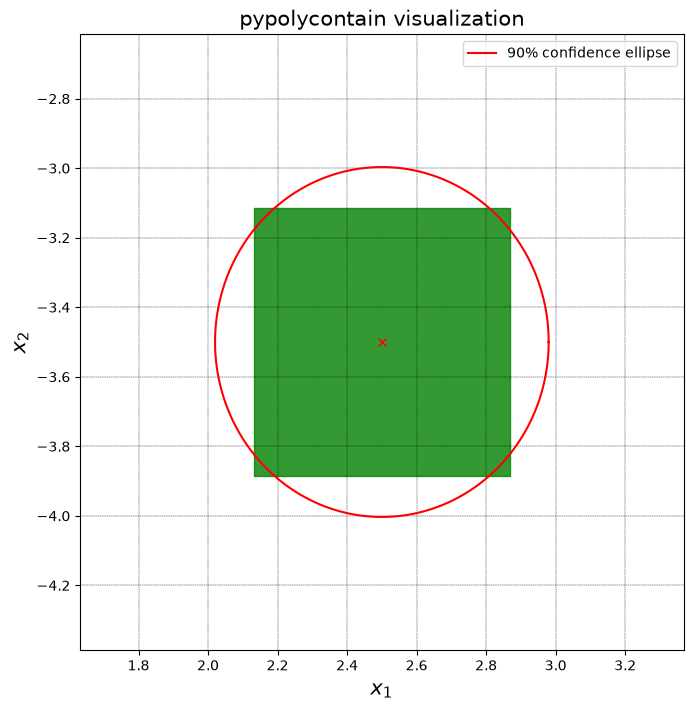

In [49]:
Sigma = np.diag([0.05, 0.055])
Mu = np.array([2.5, -3.5])

# general equation of an ellipse: (x/a)^2 + (y/b)^2 = s
s = -2 * np.log(1 - 0.9) 
semi_axes = np.sqrt(s * np.diag(Sigma)) 
major_axis = np.max(semi_axes)
minor_axis = np.min(semi_axes)

# find an enclosing 2D zonotope
# https://mediatum.ub.tum.de/doc/1554653/365916.pdf
c0 = np.array([2.5, -3.5])
g0 = np.array([[0.368, 0], [0, 0.386]])
z0 = pp.zonotope(x=c0, G=g0)

# Plotting of the zonotope and the ellipse
fig, ax = plt.subplots()
pp.visualize([z0], fig=fig, ax=ax)

theta = np.linspace(0, 2 * np.pi, 200)
ax.plot(Mu[0] + semi_axes[0] * np.cos(theta),
        Mu[1] + semi_axes[1] * np.sin(theta),
        'r', label='90% confidence ellipse')
ax.plot(*Mu, 'rx') 
ax.set_aspect('equal')
ax.legend()
plt.show()

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** The obstacle's initial position is Gaussian, while a zonotope is bounded. What does this mean for a collision-avoidance guarantee based on the chosen confidence region? If the two coordinates are independent and each interval contains 90% of its coordinate's probability, what probability does their rectangular product contain?

</div>

We use the zonotope to model the region in which we believe the initial position to be with 90% confidence per coordinate. The true position could be outside this region, though. In this case, we could miss a collision as the collision check is performed against the zonotope and we assume no collision if there is no collision with the zonotope.

As we assume 90% confidence for each dimension independently, the probability contained by the rectangle is actually $0.9 \cdot 0.9 = 0.81 = 81 \% $.

Now, let's take a step back and first generalize the results from the previous part into a function. Given some input data (see below), we want a function that returns the list of zonotopes. 

This mostly involves using the code from the previous part and turning it into a function.

In [50]:
def get_zonotopes(A,mu,c0,g0,t,r,color='g',simplify=False):
  # A: system matrix
  # mu: bounded disturbance
  # c0: initial condition
  # g0: initial generators
  # t: total simulation time
  # r: duration of time-step
  # color: the color of the zonotopes, helps distinguishing later on
  # simplify: do we lower the order of the zonotopes? (already with 2 generators so not always necessary)
  
  n = int(np.ceil(t / r - 1e-9))  # rounding up such that the last zonotope covers time t

  # bound of the disturbance box: beta_r = (e^{r||A||} - 1) / ||A|| * mu
  A_inf_norm = np.linalg.norm(A, np.inf)
  beta = (np.exp(r * A_inf_norm) - 1) / A_inf_norm * mu if A_inf_norm > 0 else r * mu
  beta_box_g = beta * np.eye(2)

  e_ra = expm(r * A)  # one-step state transition

  # Z_{k+1} = e^{rA} Z_k + Box(beta): map center and generators, append the box generators
  c_list = [np.array(c0, dtype=float)]
  g_list = [np.array(g0, dtype=float)]
  for _ in range(1, n + 1):
    c_list.append(e_ra @ c_list[-1])
    g_list.append(np.concatenate([e_ra @ g_list[-1], beta_box_g], axis=1))

  zts = []
  for c_i, g_i in zip(c_list, g_list):
    if simplify:
      # over-approximate by a rectangle (interval hull): one generator per axis
      g_i = np.diag(np.sum(np.abs(g_i), axis=1))
    zts.append(pp.zonotope(x=c_i, G=g_i, color=color))

  return zts # return the zonotopes


Now let's call the function for the object and visualize our nominally stable trajectory! 

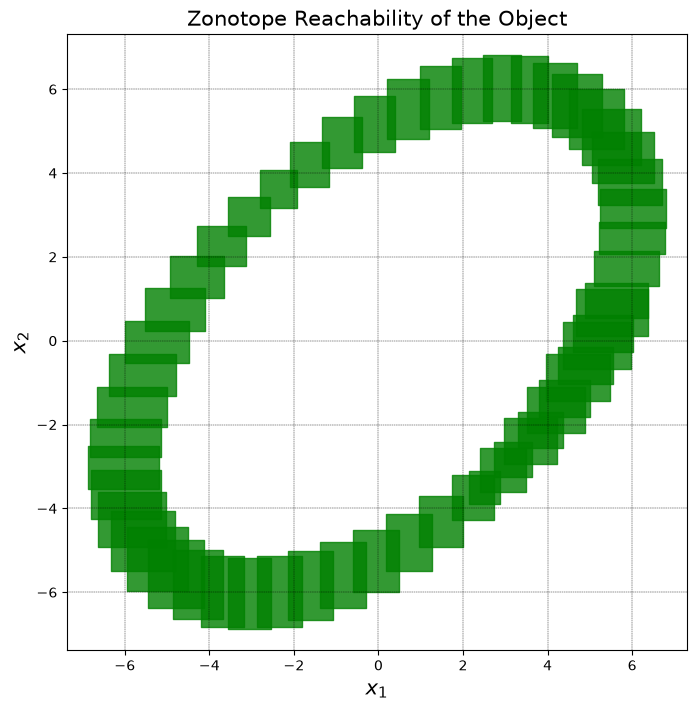

In [51]:
# duration of simulation
sim_duration = 4
r = 0.075
Ac = np.array([[1,-2],[2, -1]])
mu = 0.02 # note that this is the disturbance, not the mean

c0 = np.array([2.5, -3.5])
g0 = np.array([[0.368, 0], [0, 0.386]])  # half-widths z_p * sigma_i from the previous part

zts_obj = get_zonotopes(Ac, mu, c0, g0, sim_duration, r, color='g', simplify=True)
fig, ax = plt.subplots()
pp.visualize(zts_obj, title='Zonotope Reachability of the Object', fig=fig, ax=ax)
plt.show()


# The Robot!
Our robot model is given by a similar 2D single-integrator system. As mentioned, this is of the form

$ \dot{x}(t) = A x(t) + B u(t) + d(t)$

$ \begin{bmatrix} \dot{x} \\ \dot{y} \end{bmatrix} = \begin{bmatrix} -1 & 1 \\ -1 & 1 \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix} + \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} u_x \\ u_y \end{bmatrix} + d(t)$

which can be written in the desired autonomous form when a state-feedback control policy is applied. Our state-feedback will be obtained via [LQR](https://en.wikipedia.org/wiki/Linear%E2%80%93quadratic_regulator) which gives us an appropriate state-feedback controller given certain weights on the state deviation and the control input.

For our purposes, we wish to penalize both state-deviation and control input equally in the vertical and horizontal plane. In all situations, we do not penalize any cross-terms. For the state-deviation, we consider a weight of $50$ and for the control input a weight of $5$ respectively.

Below, implement the system and weight matrices and obtain the LQR closed-loop stabilized system by solving the continuous-time algebraic Ricatti equation using the `scipy` package. We then plot the zonotopes of the object and the robot in a single plot (use the color argument in your `get_zonotopes()` function!)

## Some intuition
While "solving the ARE" seems very arbitrary, the intuition is quite straightforward. Note that we have the optimization problem

$ \min(\int_0^{\infty} (x(t)^T Q x(t) + u(t)^T R u(t))dt )$

s.t. $\dot{x}(t) = Ax(t) + Bu(t)$

It turns out that it is easy to solve this problem as we have a quadratic cost and a linear system! The relevant steps are that we first pick a positive definite symmetric matrix $P = P^T$ and add two terms to the cost that cancel each other out

$ x_0^T P x_0 - x_0^T P x_0 + \int_0^{\infty} (x(t)^T Q x(t) + u(t)^T R u(t))dt$

for which we can take $-x_0^T P x_0$ into the integral sign. Notice that $\frac{d}{dt}(x^T P x) = \dot{x}^T P x + x^T P \dot{x}$ and $\dot{x}$ is something we already know! We get terms that depend on $u$, terms that depend on $x$, and terms that depend on both. The optimization of this unconstrained problem is significantly easier under the assumption that the control input is applied according to $u = -R^{-1}B^TPx$. If you work out the math yourself, it will lead to a cost term where the only thing we can influence is the term $\int_0^{\infty} x^T (A^TP + PA + Q - PBR^{-1}B^TP)x$ for which the term between the state $x^T$ and $x$ is the ARE.

LQR is a valuable control tool as
- It considers an optimal trade-off between user specified system requirements
- It has inherent robustness!
- It has a strong theoretical foundation with an analytical solution!

which makes it a powerful and elegant tool. We will see however, that it is not so simple to address elements commonly found in safe planning and control with pure LQR...

In the next cell, we give you a Q and R but play around with these to get a feeling of how they influence the closed-loop system!



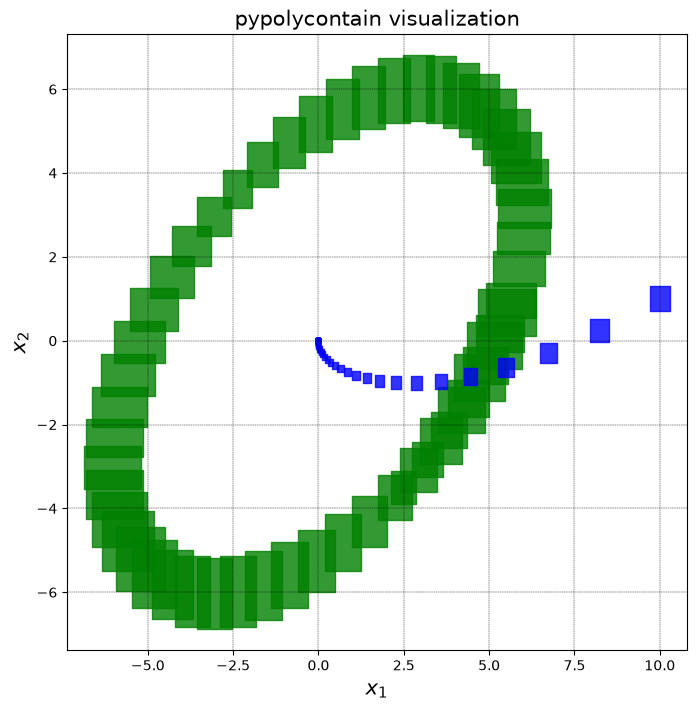

In [52]:
#PUT YOUR CODE HERE
A = np.array([[-1, 1], [-1, 1]])
B = np.array([[1, 0], [0, 1]])
Q = np.diag([120,55])
R = np.diag([20,10])
P = solve_continuous_are(A,B,Q,R)
K = np.linalg.inv(R) @ B.T @ P # from the Wikipedia article: K = -R^-1 B^T P

Ac = A - B @ K # closed-loop system

mu = 0.1

c0 = np.array([10,1])
g0 = np.array([[0.3,0],[0,0.3]])

zts_rob = get_zonotopes(Ac, mu, c0, g0, sim_duration, r, color="blue", simplify=True)

fig, ax = plt.subplots()
pp.visualize(np.append(zts_obj,zts_rob), fig=fig, ax=ax)
plt.show()


Here's an animation function which should give you some indication of what is actually going on:

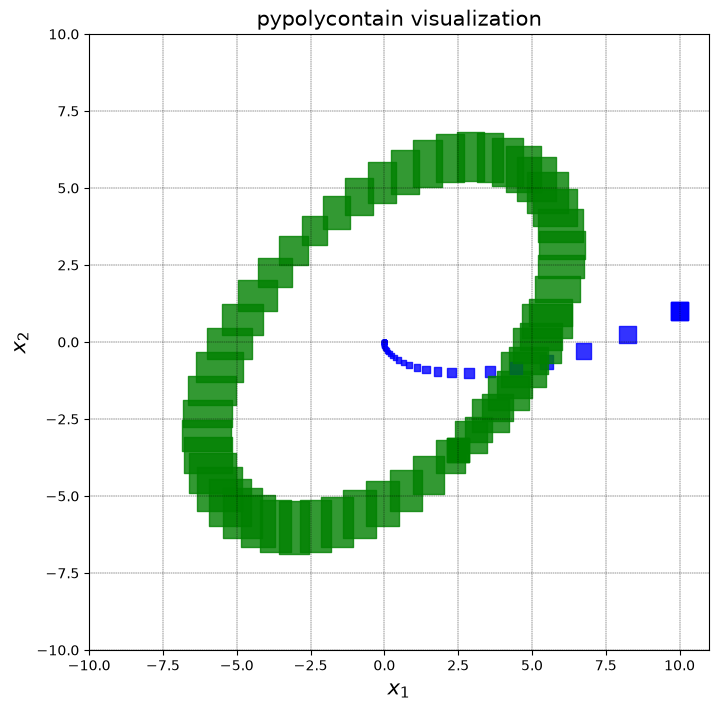

In [53]:
## ANIMATION FUNCTION
def animation_func(i,data):
  zts_obj = data[0]
  zts_rob = data[1]
  pp.visualize([zts_obj[i]], fig=fig, ax=ax)
  pp.visualize([zts_rob[i]], fig=fig, ax=ax)
  ax.set_xlim([-10, 11])
  ax.set_ylim([-10, 10])
  
fig = plt.figure()
ax = fig.add_subplot(111)
animation = FuncAnimation(fig,animation_func, fargs=((zts_obj,zts_rob),),
                          frames=len(zts_obj), interval=50, blit=False)
HTML(animation.to_html5_video())

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** With LQR feedback $u=-Kx$, the robot has closed-loop dynamics $\dot{x}=(A-BK)x+d$.

Why can we apply the same zonotope propagation method to the robot and the obstacle?

Does stabilizing the robot at the goal also ensure that its path avoids the obstacle?

</div>

Both systems are linear after closing the loop (u = −Kx gives ẋ = (A − BK)x + d). Each propagation step is a linear map e^{rA} applied to the zonotope, which maps center and generators, plus a Minkowski sum with the disturbance box, which is itself a zonotope. Zonotopes are closed under both operations, so the sets stay zonotopes and the same method works for the robot and the obstacle.

No, LQR only guarantees convergence to the origin and minimizes the state/control cost. The obstacle doesn't appear in that cost, so the controller doesn't know where it is and can't avoid it. Collision avoidance has to be verified separately instead.

# Collisions!

Given the fact that we limit ourselves to zonotopes with two generators, we can do a simple collision check on two rectangles. This involves checking overlap with 4 conditions given the center and height and width (or edge points) of the rectangles. 

Implement this very simple rectangle collision checker in a function:

In [54]:
def simple_collision_check(zts_obj,zts_rob):
  collision = False
  for i, (z_obj, z_rob) in enumerate(zip(zts_obj, zts_rob)):
    # rectangle of each zonotope: center and half-extent per axis [x, y]
    # (half-extent = sum of the absolute generator entries in each row of G)
    center_obj, center_rob = np.ravel(z_obj.x), np.ravel(z_rob.x)
    half_extent_obj = np.sum(np.abs(z_obj.G), axis=1)
    half_extent_rob = np.sum(np.abs(z_rob.G), axis=1)

    # the rectangles overlap if their intervals overlap in x and in y
    collision = (center_obj[0] - half_extent_obj[0] <= center_rob[0] + half_extent_rob[0]
                 and center_rob[0] - half_extent_rob[0] <= center_obj[0] + half_extent_obj[0]
                 and center_obj[1] - half_extent_obj[1] <= center_rob[1] + half_extent_rob[1]
                 and center_rob[1] - half_extent_rob[1] <= center_obj[1] + half_extent_obj[1])
    if collision:
      print(f"Collision at time step {i} (t = {i * r:.3f})")
      break
  if not collision:
    print("No collision")

simple_collision_check(zts_obj,zts_rob)

Collision at time step 4 (t = 0.300)


However, this does not generalize to zonotopes with many more generators. A given is that regardless of how many generators a zonotope has, the shape is always convex! As such, we can check the collision via intersection of two convex polytopes which we will construct using shapely.geometry.Polygon.

We could of course check intersection by methods that explicitly rely on zonotopes (e.g. [this](https://graphics.stanford.edu/~anguyen/papers/zonotope.pdf)). You're free to implement these methods, yet using the shapely library suffices for now. We are going to use it later on as well.

Implement this more general collision checker in a function:

In [55]:
def polygon_collision_check(zts_obj,zts_rob):
  collision = False
  for i, (zt_obj, zt_rob) in enumerate(zip(zts_obj, zts_rob)):
    # 1: get the vertices from the zonotopes
    vertices_obj = pp.zonotope_to_V(zt_obj)
    vertices_rob = pp.zonotope_to_V(zt_rob)
    # 2: convert the vertices into a shapely Polygon
    polgon_obj = MultiPoint(vertices_obj).convex_hull
    polygon_rob = MultiPoint(vertices_rob).convex_hull
    # 3: check whether a collision occured at timestep i
    if polgon_obj.intersects(polygon_rob):
      collision = True
      print(f"Collision at time step {i} (t = {i * r:.3f})")
      break
  if not collision:
    print("No collision")

polygon_collision_check(zts_obj,zts_rob)


Collision at time step 4 (t = 0.300)


Are we in collision according to your checks?
Note that the LQR controller does not take into account the obstacle at all! This is a major drawback of LQR for safe planning and control.

For the following, if you're in collision, you're good to go. Otherwise, change $Q$ and $R$ until you are in collision.

Note the old and new cost terms down somewhere!

There was no collision with the initial parameters:

$$Q_{old} = \begin{bmatrix} 120 & 0 \\ 0 & 55 \end{bmatrix}, \qquad R_{old} = \begin{bmatrix} 10 & 0 \\ 0 & 10 \end{bmatrix}$$

After increasing the $x$ entry of $R$ (from $10$ to $20$), the robot collides with the obstacle at time step 4 ($t = 0.3$). The new parameters are:

$$Q_{new} = \begin{bmatrix} 120 & 0 \\ 0 & 55 \end{bmatrix}, \qquad R_{new} = \begin{bmatrix} 20 & 0 \\ 0 & 10 \end{bmatrix}$$

Only $R_{xx}$ changed; $Q$ and the $y$ entry of $R$ stayed the same.

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** Use your collision checks to answer the following questions and explain your reasoning.

1. If the robot and obstacle zonotopes overlap for the same time interval, does this prove that a collision occurs? What can we conclude if their conservative enclosures are disjoint for every interval?
2. Could the union of the robot's reachable sets overlap the union of the obstacle's reachable sets even when every matching pair is disjoint? Explain why the time indices matter.
3. Does a zonotope with two generators necessarily form an axis-aligned rectangle? When is the simple coordinate-overlap check sufficient, and when would you use the polygon check?

</div>

1. No, in that case we only detected a collision of the enclosing zonotopes that we use to approximate their true shape. It could be the case that the collision occured with some part of the enclosure that is not actually part of the robot or the obstacle. If the enclosures are disjoint for every interval, we can conclude that there is no collision, as the enclosures contain the true reachable sets. This only holds for the confidence region we chose for the initial position and for the time intervals we actually checked.
2. Yes, the unions can overlap even though there is never an intersection at the same timestep if the intersection occurs at different times. In that case, the robot and the obstacle cross paths, but never collide as they arrive at the same point at different points in time.
3. No, a zonotope with two generators is a parallelogram in general. It is only a rectangle if the generators are orthogonal and only axis-aligned if the generators also lie along the coordinate axes. The simple coordinate-overlap check is exact if the rectangles are axis-aligned. Otherwise it uses the bounding box of the zonotope, which contains the true shape, so it never misses a collision but can report a collision that does not exist. The polygon check should be used if we need an exact answer or if the zonotopes have more generators.

# (A level) Collision! What to do now?
What you have been doing so far is often referred to as $\textit{verification}$ process since you are using the knowledge of your system to analyze whether some desired specification (do not collide with an obstacle) holds or not.

In the next couple of steps, you're gonna look into the so called $\textit{synthesis}$ process in which you are given a desired system specification and you design a control strategy $u$ such that the specification holds. Specifically, you're gonna design different Control Barrier Functions (CBFs) to guarantee that the robot stays within an obstacle-free safeset. CBFs have been covered in the lectures but if you would like to refresh your knowledge you might want to have a look at [this](https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=8796030&casa_token=CtgTXVjMhTAAAAAA:93TomzH638Rg17rJl9LRW5WYljATBuiBor0OkfvSXwvZ-Y0rO-xkOhK15JBWIqrcIDgnqlEX) publication.

# Simple yet provably safe controller
First, we will design a very conservative barrier function. In this case, we would like to obtain a halfspace constraint that contains all possible obstacle locations. If we can design a controller that stays within this obstacle-free halfspace, we are guaranteed to avoid collisions.


Such a halfspace can be defined as $\mathcal{H} = \left\{ x \in \mathbb{R}^n \mid a^T x \leq b\right\}$. Recall, that any polygon can also be written as an intersection of halfspaces. Convince yourself that the convex hull of all obstacle location from $t=0, \dots , T$ contains all possible locations the obstacle might be at. In the following, try to find this convex polygon and visualize it!

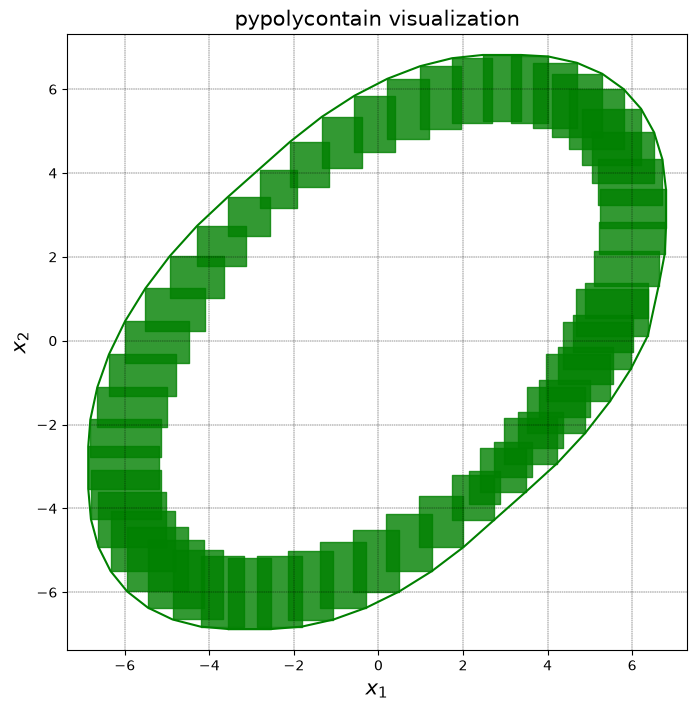

In [56]:
# trajectory of the obstacle in V-form
obj_trajectory = [pp.zonotope_to_V(zts_obj[i]).tolist()[j] for i in range(len(zts_obj)) for j in range(4)]

# convex hull of obstacle trajectory
conv_hull_obj = MultiPoint(obj_trajectory).convex_hull

# Visualization
x,y = conv_hull_obj.exterior.coords.xy

pp.visualize(zts_obj)
plt.plot(x,y,'g')
plt.show()

Next, in order to define our barrier function, we need the convex hull of the obstacle trajectory in halfspace form (H-polytope). Unfortunately, the function provided in `pypolycontain` does not work properly, so we have to do the conversion ourselves. Recall that each edge of the polytope between two consecutive vertices $V_i$ and $V_{i+1}$ can be described as a linear function of the form $a^T x - b = 0$.

Note, that the convex hull has many vertices, so we would like to create a list of tuples that contains all the halfspaces $halfspaces = [(a_0, b_0), \dots, (a_{N-1}, b_{N-1})]$ where $N$ is the number of vertices. Since it can be tideous to find the correct sign of the halfspaces, this function is provided in the following. Try to understand the code!

/tmp/ipykernel_6033/1387564208.py:16: RuntimeWarning: invalid value encountered in scalar divide
  a = [-dy / abs(dx), 1]


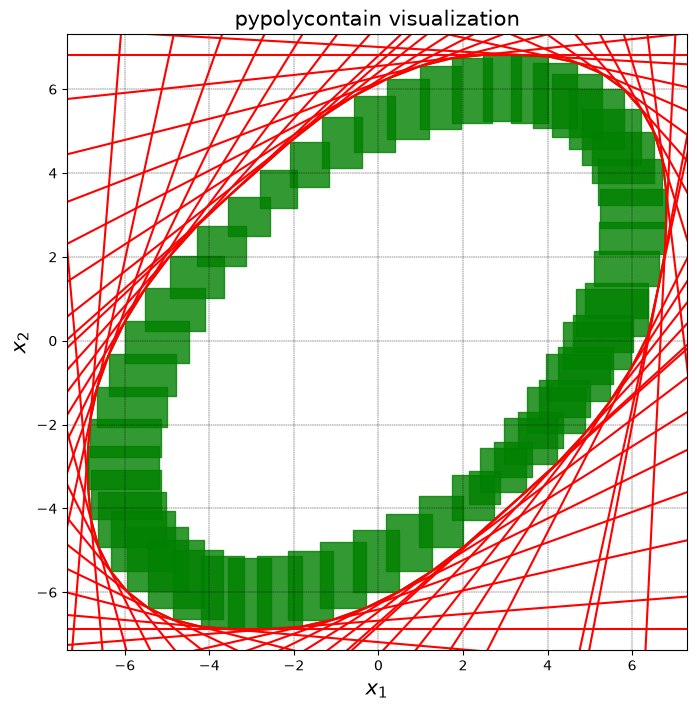

In [57]:
vertices = np.array([[x[i], y[i]] for i in range(len(x))])

def construct_halfspaces(vertices_list):
  halfspaces = []

  for i in range(len(vertices_list)-1):
    # vertex i
    p1 = vertices[i]
    # vertex i+1
    p2 = vertices[i+1]

    # change in x and y
    dx = p2[0] - p1[0]
    dy = (p2[1] - p1[1]) * np.sign(dx)

    a = [-dy / abs(dx), 1]
    b = a[0] * p1[0] + a[1] * p1[1]
    if dx < 0:
      a = [-a[0], -a[1]]
      b *= -1
    halfspaces.append((a, b))

  return halfspaces

halfspaces = construct_halfspaces(vertices.tolist())

# visualize all the halfspaces
pp.visualize(zts_obj)
plt.plot(x,y,'g')
for ab in halfspaces:
  plt.plot([-10,10], [(ab[1] - ab[0][0] * (-10)) / ab[0][1], (ab[1] - ab[0][0] * (10)) / ab[0][1]], 'r')
plt.show()


Now, any of these halfspaces could be used as a candidate CBF since the intersection of all halfspaces $\mathcal{O} = \left\{x \in \mathbb{R}^n \mid \bigwedge_{i=0}^{N-1} a_i^T x \leq b_i \right\}$ represents the obstacle region and, thus, if any of the halfspace constraints is violated, i.e. $\bigvee_{i=0}^{N-1} a_i^T x \geq b_i$, then the robot is outside of the obstacle region $\mathcal{O}$.

The question that remains is: Which one is the most suitable halfspace constraint? It's a design choice! We would like to obtain a halfspace that contains the initial position of the robot $x_0$ and allows us to get as close as possible to the goal $g = [0, 0]$. Hint: use the distance between a point and a line!

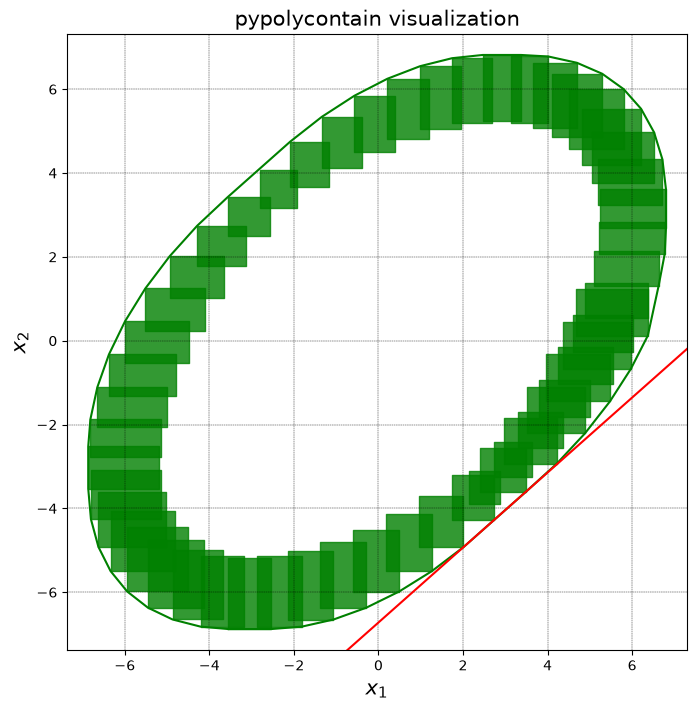

In [58]:
a_min = None
b_min = None
min_dist = math.inf
for (a_candidate, b_candidate) in halfspaces:
    # a^T x <= b is the obstacle side (hull), so the robot's safe side is a^T x >= b
    if np.dot(a_candidate, c0) >= b_candidate:
        dist_candidate = np.max([0, (b_candidate - np.dot(a_candidate, np.array([0,0]))) / np.linalg.norm(a_candidate)])
        if dist_candidate < min_dist:
            a_min = a_candidate
            b_min = b_candidate 
            min_dist = dist_candidate


pp.visualize(zts_obj)
plt.plot(x,y,'g')
plt.plot([-10,10], [(b_min - a_min[0] * (-10)) / a_min[1], (b_min - a_min[0] * (10)) / a_min[1]], 'r')
plt.show()


Let's define our CBF! Remember, the safeset which we would like to render invariant (basically means if we are inside the set, we will remain in the set) is of the form

$\mathcal{C} = \left\{x \in \mathbb{R}^n \mid h\left(x, t\right) \geq 0 \right\}$

where our barrier function $h$ might depend explicitly on time. In our first scenario, however, we generate a constant CBF so there won't be any time dependencies.

In [59]:
# The safe set is the halfspace a_min^T x >= b_min: a^T x <= b describes the obstacle (hull) side,
# so the robot has to stay on the other side. CBFs need h(x) >= 0 to mean "safe", so
#   a^T x >= b  <=>  a^T x - b >= 0   ->   h(x) = a^T x - b
# Derivatives for the safety filter: dh/dx = a, dh/dt = 0 (static barrier, no time dependence).
h_static = lambda x, t: np.dot(a_min, x) - b_min

## Control Synthesis!
Now that we've defined our CBF, we need to synthesize control inputs $u$ which render $\mathcal{C}$ invariant. Have a look at the lectures (or the linked paper) again and convince yourself that 

$\dot{h}\left(x, t\right) \geq - \gamma h\left(x, t\right)$

ensures invariance. By applying the chain rule to the above constraint, we can obtain an expression

$\dot{h}(x, t) = \frac{\partial h }{\partial x} \dot{x} + \frac{\partial h}{\partial t} = \frac{\partial h }{\partial x} (Ax + Bu + d) + \frac{\partial h}{\partial t} \geq -\gamma h(x, t)$

which is linear in the control input and, thus, this constraint can be included in convex optimization problems!

Basically, what we want to do now is to develop a safety filter that takes as input a reference control input $u_{ref}$, e.g. the LQR control input, and outputs a safe control input that satisfies the safety constraint. Additionally, this modified control input should be as close as possible to the reference input so that the robot follows its reference controller and the safety filter only intervenes if we're about to violate the safety specification. This can be formulated as an optimization problem

$$
\begin{aligned}
	\min_{u} \quad &(u - u_{ref})^T Q (u - u_{ref})\\
	\textrm{s.t.  } \quad  &\frac{\partial h }{\partial x} (Ax + Bu + d) + \frac{\partial h}{\partial t} \geq - \gamma h(x, t)
    \end{aligned}.
$$

which is a quadratic program (QP) and, thus, can be solved efficiently. For the following simulations simply assume that the robot disturbance is zero, i.e. $d=0$.

In order to solve the optimization problem, we will make use of python convex optimization package `cvxopt`. Please have a look at [this](https://cvxopt.org/examples/tutorial/qp.html) example of how to formulate and solve a QP in python. Hint: formulate the optimization using the decision variable $\tilde{u} = u - u_{ref}$ which requires slight modification of the safety constraint.

In [60]:
# Some imports for the CBF formulation
from scipy.integrate import odeint
from math import sin, cos, sqrt, atan2, pi
from cvxopt import matrix, solvers

Let's define the function of the safety filter!

In [61]:
def safety_filter(x, h, t):
    gamma = 10
    x = np.asarray(x, dtype=float)

    # reference control input (LQR from above)
    u_ref = -K @ x

    # Barrier condition dhdx * (f(x) + g(x) u) >= -gamma * h(x), with f(x) = A x, g(x) = B (d = 0)
    # dh/dx and dh/dt via central differences (exact for the linear static h, also works for a time-varying h)
    eps = 1e-6
    dhdx = np.array([(h(x + eps * e, t) - h(x - eps * e, t)) / (2 * eps) for e in np.eye(len(x))])
    dhdt = (h(x, t + eps) - h(x, t - eps)) / (2 * eps)

    # set up QP in u_tilde = u - u_ref:
    #   min  u_tilde^T Q u_tilde
    #   s.t. dhdx B u_tilde >= -gamma h - dhdx (A x + B u_ref) - dhdt
    #   <=>  (-dhdx B) u_tilde <= gamma h + dhdx (A x + B u_ref) + dhdt
    Q = np.eye(2)
    p = np.zeros(2)
    G = -(dhdx @ B).reshape(1, 2)
    b_qp = np.array([gamma * h(x, t) + dhdx @ (A @ x + B @ u_ref) + dhdt])

    solvers.options['show_progress'] = False
    # cvxopt minimizes 1/2 u^T P u + q^T u, hence P = 2 Q
    sol = solvers.qp(matrix(2 * Q), matrix(p), matrix(G), matrix(b_qp))
    u_tilde = np.array(sol['x']).flatten()
    u_safe = u_ref + u_tilde

    return u_safe

Now we're gonna run a simple simulation which should show that the static halfspace constraint is always satisfied. To do so, we need to define the closed loop system and call a differential equation solver!

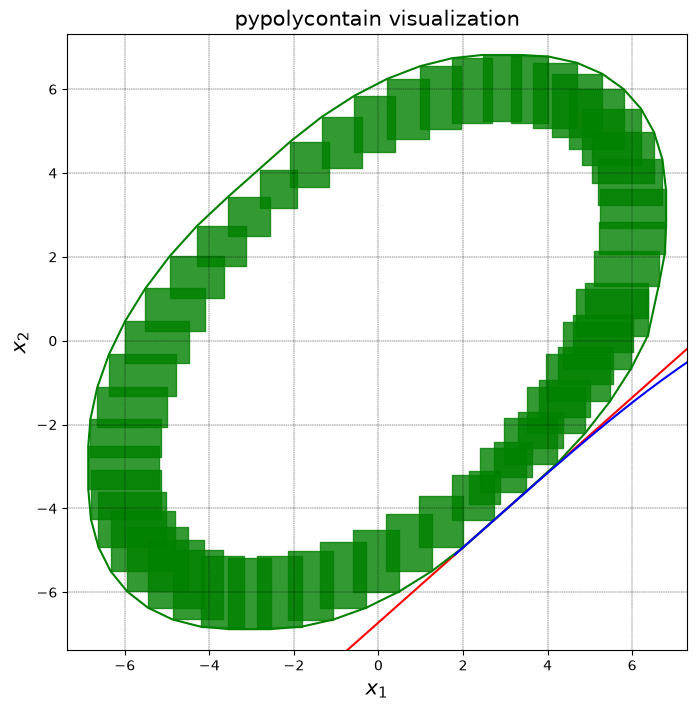

In [62]:
def closed_loop_system(x, t):
  # controller
  u = safety_filter(x, h_static, t)
  dx = A @ x + B @ u
  return dx

# Initial Conditions
t_sim = np.linspace(0, sim_duration, 300)


x_sol = odeint(closed_loop_system, c0, t_sim)

fig, ax = plt.subplots()
pp.visualize(zts_obj, fig=fig, ax=ax)
plt.plot([-10,10], [(b_min - a_min[0] * (-10)) / a_min[1], (b_min - a_min[0] * (10)) / a_min[1]], 'r')
plt.plot(x,y,'g')
plt.plot(x_sol[:, 0], x_sol[:, 1], 'b')
plt.show()

## Let's see an animated version!
It might take a while to visualize.

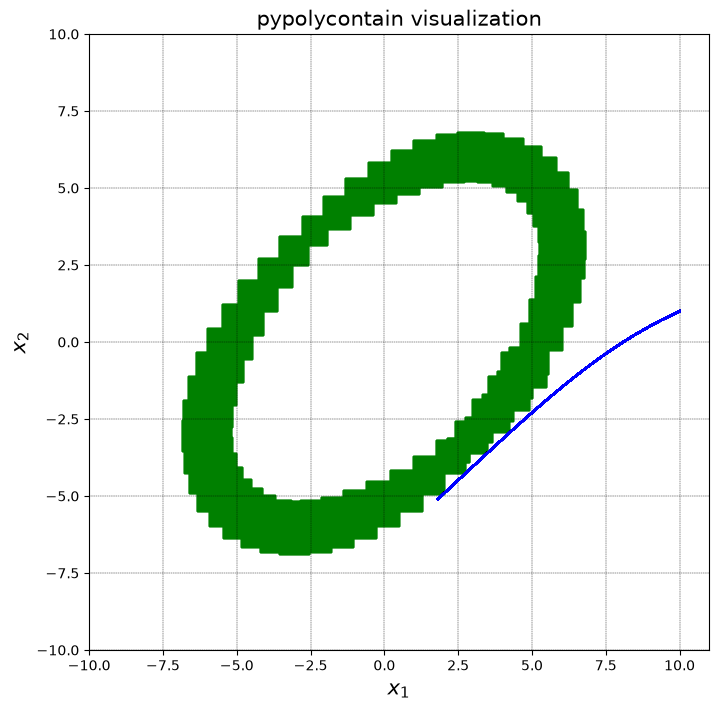

In [63]:
## ANIMATION FUNCTION
def animation_func(i,data):
  current_t = i * (sim_duration / len(t_sim))
  zts_obj = data[0]
  robot_pos = data[1]
  pp.visualize([zts_obj[min(len(zts_obj)-1, int(np.floor(current_t / r)))]], fig=fig, ax=ax)
  plt.plot(robot_pos[0:i, 0], robot_pos[0:i, 1], 'b')
  ax.set_xlim([-10, 11])
  ax.set_ylim([-10, 10])
  
fig = plt.figure()
ax = fig.add_subplot(111)
animation = FuncAnimation(fig,animation_func, fargs=((zts_obj,x_sol),),
                          frames=len(t_sim)-1, interval=50, blit=False)
HTML(animation.to_html5_video())

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** The static barrier keeps the robot on the exterior side of one face of the convex hull of the obstacle's reachable sets. Why does this ensure separation under the model assumptions? Explain how this construction can prevent the robot from reaching the goal even after the obstacle has moved away.

</div>

The convex hull contains all reachable sets of the obstacle over the whole time horizon and it lies entirely on one side of each of the halfspaces. The barriers keep the robot on the other side of each halfspace. Therefore, the robot can never cross any barrier. As the obstacle traces an ellipse over the whole time horizon, the barriers prevent the robot from entering it, but the goal is inside that ellipse. Thus, the robot can never reach the goal. We don't consider the movement of the obstacle over time though and thus miss the time window during which it could safely pass the hull as the obstacle has not yet arrived at that point or it has already crossed the point.

## Safe? yes! Is it what we want? No..
From this simulation we can observe that the robot indeed stays safe at all time, i.e. it does not collide with the dynamic obstacle. However, it is also rather conservative since the robot stays in the safe halfspace although the obstacle is far away. How can we change that? The key is to consider a timevarying control barrier function that changes whenever the obstacle is moving. In this section we will look into more sophisticated CBFs that will change over time. In this way, we will not only ensure safety but also ensure that our robot reaches its destination!

One requirement of a valid CBF is that it's continuous in time and continuously differentiable with respect to $x$ and $t$. Since we only have the obstacle zonotopes at discrete time steps, we will use a simple linear time interpolation for the obstacle between time steps $t_k$ and $t_{k+1}$.

The following function takes the current time as well as the list of discrete zonotopes and returns a polytope in vertex form (V_polytope) at the current time.

In [65]:
def cont_time_obstacle(t, zonotopes_obst):
  # Use simple linear interpolation
  ind = int(np.floor(t / r))
  last = min(ind, len(zonotopes_obst) - 1)
  nxt = min(ind + 1, len(zonotopes_obst) - 1)  # hold the last set if t runs past the horizon
  t_last = ind * r
  t_next = (ind + 1) * r
  obst_last = pp.zonotope_to_V(zonotopes_obst[last])
  obst_next = pp.zonotope_to_V(zonotopes_obst[nxt])
  # obstacle at current time t as V-representation:
  # interpolate every vertex linearly between the two neighbouring time steps
  alpha = (t - t_last) / (t_next - t_last)
  obst_t = (1 - alpha) * obst_last + alpha * obst_next

  return obst_t

Now we have a function to call that provides us with a polytope representation of the obstacle at any time. However, we still need to ensure that our robot is always outside of the polytope. There are different ways to ensure collision avoidance, e.g. taking the distance between a point and a polygon. However, this would be a nonsmooth measure in $x$ which is why we consider an overapproximating circle in the following.

Find the smallest circle that contains the entire polytope at time t!

In [66]:
def bounding_radius(t, zonotopes_obst):
  # Use simple linear interpolation
  ind = int(np.floor(t / r))
  t0 = ind * r
  t1 = (ind+1) * r
  
  # Zonotope centers
  z_c0 = zonotopes_obst[min(ind, len(zts_obj)-1)].x
  z_c1 = zonotopes_obst[min(ind+1, len(zts_obj)-1)].x


  # center of zonotope at time t
  z_c = z_c0 + ((z_c1 - z_c0) / (t1 - t0)) * (t - t0)

  r_bound = np.max(np.linalg.norm(cont_time_obstacle(t, zonotopes_obst) - z_c, axis=1))

  return z_c, r_bound

# TEST
print(bounding_radius(1, zts_obj))

(array([5.00297655, 5.39555555]), np.float64(0.9608835308814647))


Let's check if our bounding circle algorithm works properly!

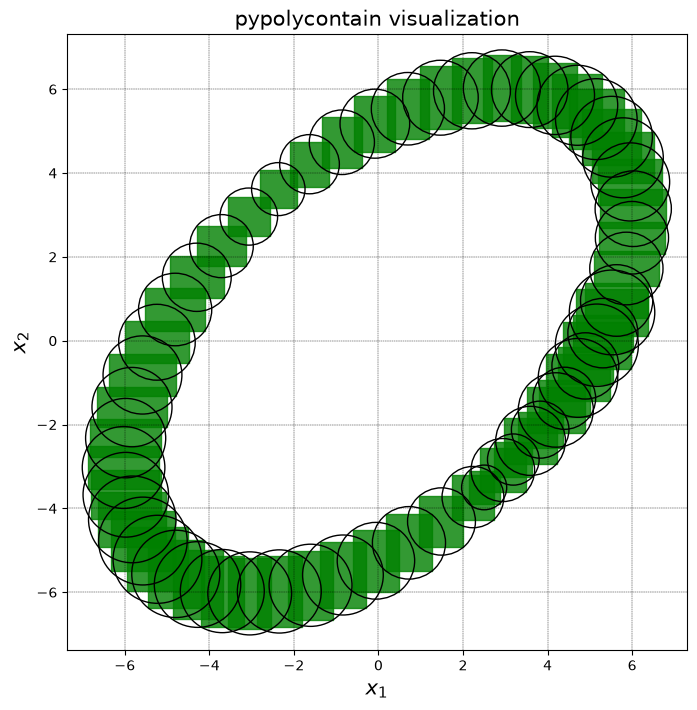

In [67]:
from matplotlib.patches import Circle

fig, ax = plt.subplots()
pp.visualize(zts_obj, fig=fig, ax=ax)
for i in range(len(zts_obj)):
  tnow = i * r
  center, radius = bounding_radius(tnow, zts_obj)
  ax.add_artist(Circle(center, radius, fill=False))
plt.show()

In the case of a CBF that explicitly depends on time, we need to to account for the known change of the obstacle over time. In this case, the explicit CBF time derivative $\frac{\partial h}{\partial t}$ is nonzero.

However, since the explicit time dependency is not exactly known in our case (as a result of discrete reachibility analysis and time interpolation), we approximate the time derivative of the barrier function using finite differences. To be specific, we will use a simple forward difference method

$\frac{\partial f}{\partial t} (t) \approx \frac{f\left(t + \delta t\right) - f\left(t\right)}{\delta t}$.

The CBF we consider is given as

$h(x, t) = \lVert x - c_{obs}(t) \rVert_2 - r_{obs}(t) \geq 0$

In the following, write a function that returns the value of the CBF $h(x, t)$, its gradient $\frac{\partial h}{\partial x}$ as well as its explicit time derivative $\frac{\partial h}{\partial t}$. Hint: you need to apply the chain rule for the gradient and the time derivative. Approximate explicit time derivatives $\frac{\partial c_{obs}}{\partial t}$ and $\frac{\partial r_{obs}}{\partial t}$ using finite differences.

In [68]:
def cbf_dynamic(x, t):
  # Input: state defined as x = [x_robot, y_robot]
  # Output: Value of CBF h(x), gradient with respect to x dhdx(x), explicit time derivative dhdt
  x = np.asarray(x, dtype=float)
  dt = 1e-4  # step of the forward difference

  # moving bounding circle of the obstacle at time t and t + dt
  c_obs, r_obs = bounding_radius(t, zts_obj)
  c_next, r_next = bounding_radius(t + dt, zts_obj)
  c_obs, c_next = np.ravel(c_obs), np.ravel(c_next)

  # forward differences of the circle center and radius
  dcdt = (c_next - c_obs) / dt
  drdt = (r_next - r_obs) / dt

  # h(x, t) = ||x - c_obs(t)|| - r_obs(t)
  diff = x - c_obs
  dist = np.linalg.norm(diff)
  h_val = dist - r_obs

  # chain rule: dh/dx = (x - c)/||x - c||,  dh/dt = -(x - c)^T/||x - c|| * dc/dt - dr/dt
  dhdx = diff / dist
  dhdt = -dhdx @ dcdt - drdt

  return h_val, dhdx, dhdt


#Test
print(cbf_dynamic(c0, 0))

(np.float64(8.213117426093655), array([0.85749293, 0.51449576]), np.float64(-13.454546082650058))


Now, we will define the safety filter similarly to the safety filter using the static CBF. Set up the QP and run the continuous time simulation. What can you observe? Try different parameter settings for $\gamma = [1, 10, 30]$. Also, plot the value of $h(x, t)$ over time for different values of $\gamma$. What is the trade-off when choosing large values of $\gamma$?

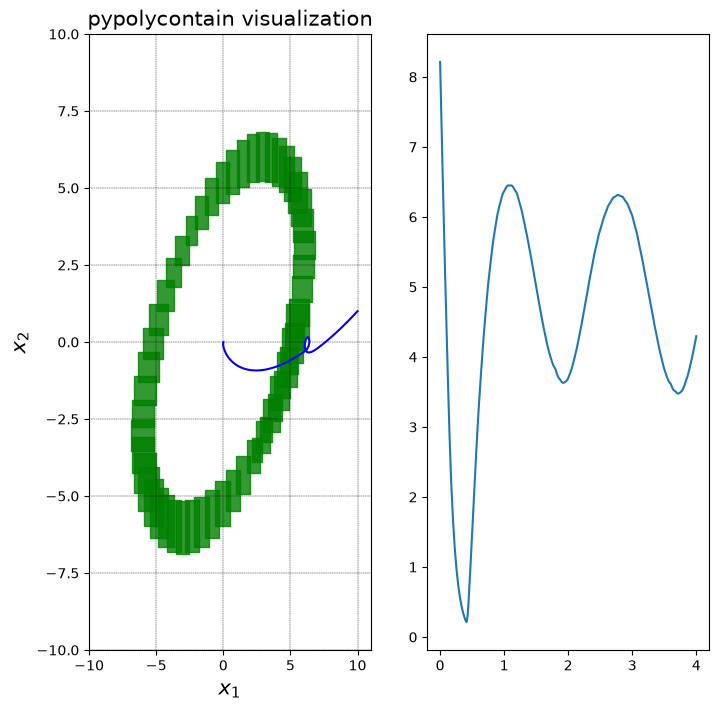

In [69]:
def safety_filter(x, t, gamma=10):
  x = np.asarray(x, dtype=float)

  # reference control input (LQR)
  u_ref = -K @ x

  # time-varying CBF: value, gradient and explicit time derivative
  h_val, dhdx, dhdt = cbf_dynamic(x, t)

  # QP in u_tilde = u - u_ref (robot dynamics A x + B u, d = 0):
  #   min  u_tilde^T Q u_tilde
  #   s.t. dhdx (A x + B u) + dhdt >= -gamma h
  #   <=>  (-dhdx B) u_tilde <= gamma h + dhdx (A x + B u_ref) + dhdt
  Q = np.eye(2)
  p = np.zeros(2)
  G = -(dhdx @ B).reshape(1, 2)
  b_qp = np.array([gamma * h_val + dhdx @ (A @ x + B @ u_ref) + dhdt])

  solvers.options['show_progress'] = False
  sol = solvers.qp(matrix(2 * Q), matrix(p), matrix(G), matrix(b_qp))  # cvxopt minimizes 1/2 u^T P u + q^T u
  u_safe = u_ref + np.array(sol['x']).flatten()
  return u_safe

# closed loop dynamics including CBF controller
def closed_loop_system(x, t, gamma=10):
  u = safety_filter(x, t, gamma)
  dx = A @ x + B @ u
  return dx

# Initial Conditions
t_sim = np.linspace(0, sim_duration, 300)

x_sol = odeint(closed_loop_system, c0, t_sim)

fig = plt.figure() 
ax = fig.add_subplot(121)
pp.visualize(zts_obj, fig=fig, ax=ax)
plt.plot(x_sol[:, 0], x_sol[:, 1], 'b')
ax.set_xlim([-10, 11])
ax.set_ylim([-10, 10])
ax2 = fig.add_subplot(122)
plt.plot(t_sim, [cbf_dynamic(x_sol[i], t_sim[i])[0] for i in range(len(t_sim))])
plt.show()

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** For the moving-circle barrier $h(x,t)=\|x-c_{obs}(t)\|_2-r_{obs}(t)$, explain the role of the explicit time derivative $\partial h/\partial t$ in the safety constraint. What could go wrong if we omitted it while the obstacle moved toward a stationary robot or its uncertainty radius increased?

</div>

The explicit time derivative captures how $h$ changes because of the movement of the barrier itself or a change in its bounding radius. If we'd not consider it, we could miss a collision with a stationary robot by the obstacle moving towards it or its enclosing circle increasing towards the robot. This could cause a collision if the robot doesn't move to get out the way.

Lastly, we can see our robot in action! In this simulation section, you have been working on safe control synthesis in a reactive setting meaning that obstacle avoidance is guaranteed but it also could have been avoided at all if this problem would have been tackled at a higher level such as motion planning. Nonetheless, CBFs are an amazing tool for safety guarantees on a control level. There are many different topics that you could explore from here, e.g. robust CBFs, CBFs under uncertainties, CBFs for multi-agent systems, CBFs for safe reinforcement learning and many more!

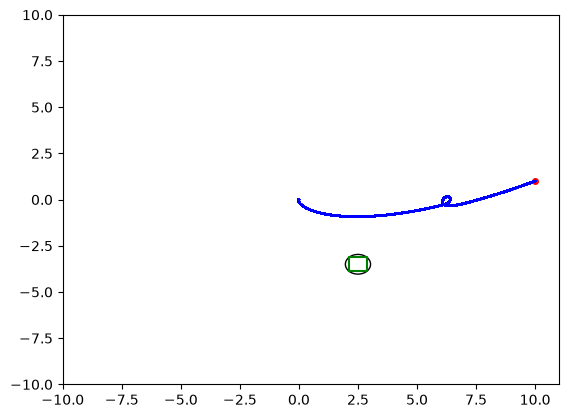

In [70]:
## ANIMATION FUNCTION
def animation_func(i,data):
  # visualize robot 
  robot_pos = data
  plt.plot([robot_pos[k][0] for k in range(i)], [robot_pos[k][1] for k in range(i)], 'b')
  
  current_t = i * (sim_duration / len(t_sim))
  
  # visualize obstacle set
  current_obs = cont_time_obstacle(current_t, zts_obj)
  conv_hull_obj = MultiPoint(current_obs).convex_hull
  x,y = conv_hull_obj.exterior.coords.xy
  poly_plot.set_xdata(x)
  poly_plot.set_ydata(y)

  c_obs, r_obs = bounding_radius(current_t, zts_obj)
  patch.center = c_obs
  patch.radius = r_obs

  ax.set_xlim([-10, 11])
  ax.set_ylim([-10, 10])
  
fig = plt.figure()
ax = fig.add_subplot(111)
conv_hull_obj = MultiPoint(cont_time_obstacle(0, zts_obj)).convex_hull
x,y = conv_hull_obj.exterior.coords.xy
poly_plot, = plt.plot(x, y, 'g')
plt.plot([c0[0]], [c0[1]], marker='o', markersize=4, c='r')

# Visualize circle
c_obs, r_obs = bounding_radius(0, zts_obj)
patch = Circle(c_obs, r_obs, fill=False)
ax.add_artist(patch)


animation = FuncAnimation(fig,animation_func, fargs=((x_sol),),
                          frames=len(x_sol), interval=50, blit=False)
HTML(animation.to_html5_video())

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** The safety-filter simulations assume zero robot disturbance and impose no input bounds.

1. If a bounded disturbance acted on the robot, how would you modify the barrier constraint to account for its worst effect on $\dot h$?
2. If control inputs were bounded, could the quadratic program become infeasible even with $h(x,t)\ge0$? Describe a situation where this could happen.
3. Does avoiding the obstacle imply that the robot reaches the goal? Explain what the safety constraint does and does not establish.

</div>

1. The disturbance enters through $\dot{x} = Ax + Bu + d$, so I'd require the barrier constraint to hold for the worst case $\lVert d\rVert \le d_{max}$. This subtracts a worst-case term from the left-hand side: $\frac{\partial h}{\partial x}(Ax + Bu) + \frac{\partial h}{\partial t} - \left\lVert \frac{\partial h}{\partial x} \right\rVert d_{max} \geq -\gamma h$. For the circle barrier $\lVert \partial h/\partial x \rVert = 1$, so this simply subtracts $d_{max}$.
2. Yes, if the bound is too restrictive, such that the robot can't move away from an obstacle that's approaching it quickly enough or it can't break in time until it hits an obstacles. In that case a collision would be unavoidable.
3. No, the safety constraint just assures that no collision with the obstacles happens. It does not guarantee that the robot reaches the goal, these are separate problems.